# multimodel_analysis - Phase 7: anomaly detection, dimensionality reduction, explainability and the HTML report
Four additions in this release:

1. **`MultiModelAnomalyDetector`** - finds the strange rows in your data with six detectors at once.
2. **`MultiModelReducer`** - squeezes many features into 2-3 for plotting or modelling, and tells you which method kept the most information.
3. **Explainability** for the classifier and regressor - *which features matter* and *how a feature changes the prediction*.
4. **`save_html_report()`** - one self-contained HTML file with the table and all plots, for anyone who does not run Python.

In [1]:
%matplotlib inline
import os, tempfile
import numpy as np
import pandas as pd
from sklearn.datasets import load_breast_cancer, load_diabetes, load_digits, load_iris, make_swiss_roll
import multimodel_analysis as mm
from multimodel_analysis import (MultiModelAnomalyDetector, MultiModelReducer,
                                 MultiModelClassifier, MultiModelRegressor, MultiModelClusterer)
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 30)
print('multimodel_analysis', mm.__version__)

multimodel_analysis 0.6.0


# Part 1 - Anomaly detection
There is no "right answer" column in most real data, so every detector is asked the same question: *which rows are the strangest?* Each model flags the **same share of rows** (`contamination`), which makes the models directly comparable.

If you happen to know the true anomalies you can pass them as `y` (1 = anomaly, 0 = normal) - they are never used for fitting, only to score the detectors.

In [2]:
print('standard set :', MultiModelAnomalyDetector.default_models())
print('everything    :', MultiModelAnomalyDetector.available_models())

standard set : ['isolation_forest', 'lof', 'one_class_svm', 'elliptic_envelope', 'knn_distance', 'robust_zscore']
everything    : ['isolation_forest', 'lof', 'one_class_svm', 'elliptic_envelope', 'knn_distance', 'robust_zscore', 'sgd_one_class_svm']


## 1.1 With known anomalies
Three correlated sensor readings; 300 normal rows and 15 faulty ones that sit far away.

In [3]:
rng = np.random.RandomState(0)
normal = rng.multivariate_normal([0, 0, 0], [[1, .6, .2], [.6, 1, .3], [.2, .3, 1]], 300)
faulty = rng.randn(15, 3) * 0.5 + [4, -4, 4]
sensors = pd.DataFrame(np.vstack([normal, faulty]), columns=['temperature', 'pressure', 'vibration'])
is_fault = np.r_[np.zeros(300, int), np.ones(15, int)]

det = MultiModelAnomalyDetector(sensors, y=is_fault, random_state=0, verbose=False)
models = det.run_all_models()
df = det.show_tabular_report(models, return_df=True)


 ANOMALY DETECTOR COMPARISON 
               Model  Anomalies  Anomaly Rate (%)  Agreement  Precision  Recall  F1 Score  ROC AUC  Avg Precision  Fit Time (s)
    Isolation Forest         15            4.7619     0.9561     1.0000  1.0000    1.0000   1.0000         1.0000        0.1706
   Elliptic Envelope         15            4.7619     0.9763     1.0000  1.0000    1.0000   1.0000         1.0000        0.0275
      Robust Z-Score         15            4.7619     0.8679     1.0000  1.0000    1.0000   1.0000         1.0000        0.0003
Local Outlier Factor         15            4.7619     0.9478     0.8667  0.8667    0.8667   0.9967         0.9018        0.0150
        KNN Distance         15            4.7619     0.9641     0.6667  0.6667    0.6667   0.9769         0.6760        0.0024
       One-Class SVM         15            4.7619     0.7562     0.1333  0.1333    0.1333   0.9049         0.2723        0.0010

* BEST MODEL (by F1 Score): Isolation Forest
  Every model flags the top

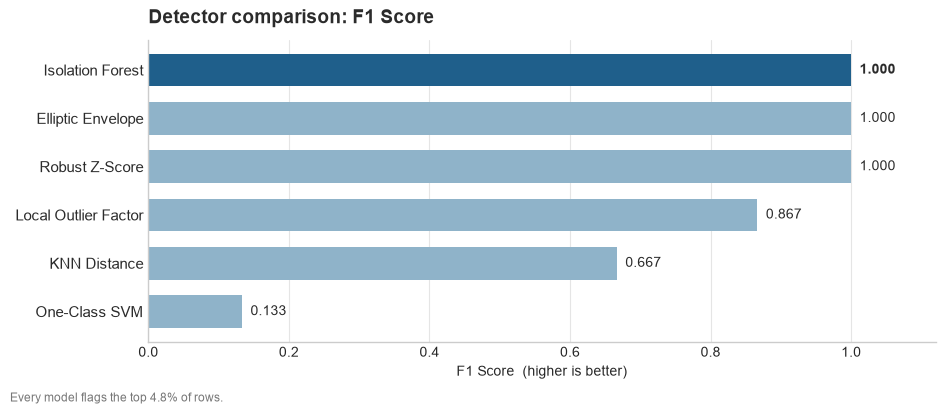

In [4]:
det.plot_comparison(models)

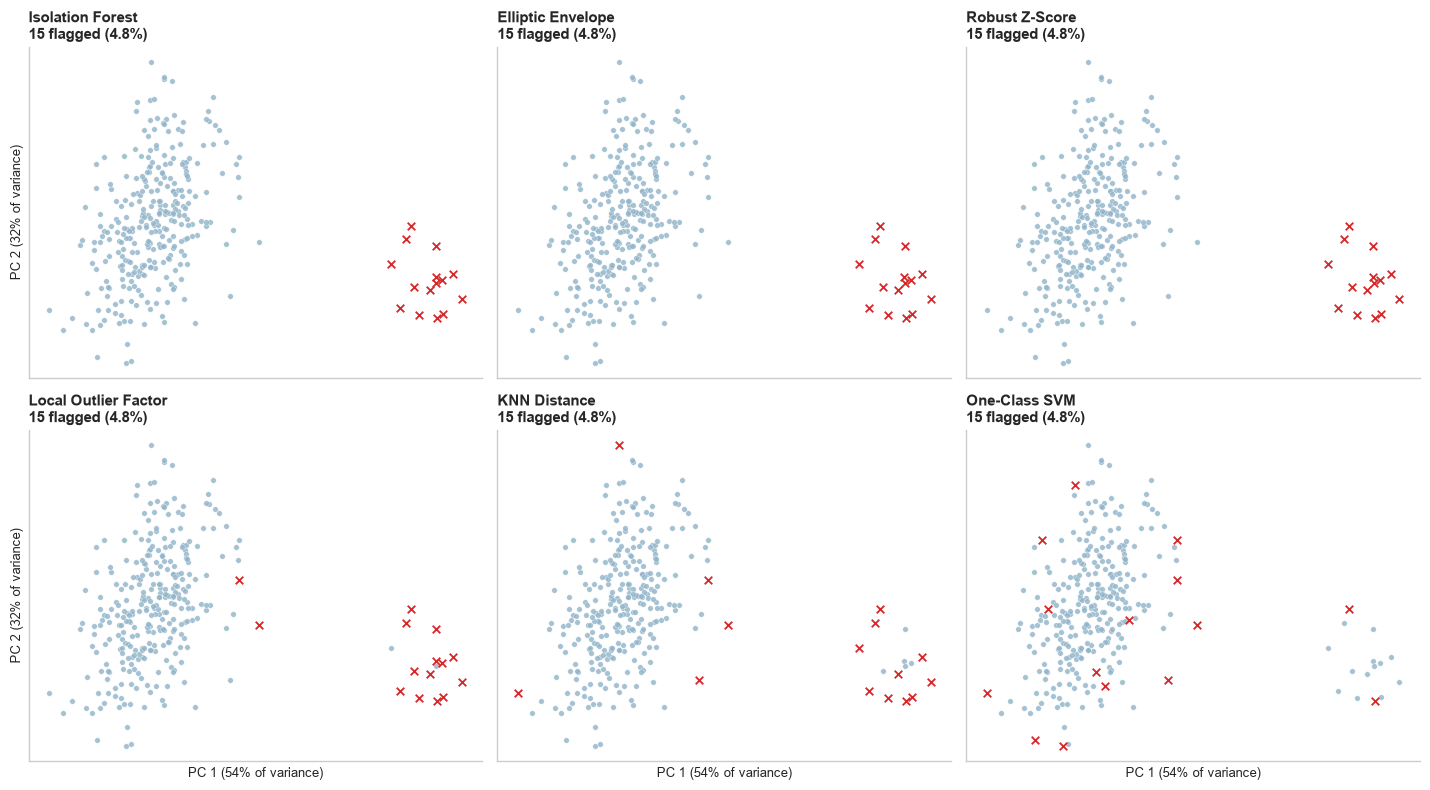

In [5]:
det.plot_anomalies(models)

### The strangest rows
`top_anomalies()` gives your original values plus the score; `assign_anomalies()` adds `anomaly` and `anomaly_score` columns to the whole table.

In [6]:
det.top_anomalies(5)

,temperature,pressure,vibration,anomaly,anomaly_score
304,4.515219,-5.023662,3.386689,1,0.678413
301,4.095156,-4.425865,4.911362,1,0.677269
303,4.664531,-4.408747,3.299326,1,0.656117
310,4.796385,-4.129286,4.154166,1,0.647874
307,4.638038,-3.337493,4.102666,1,0.646852


In [7]:
det.assign_anomalies().groupby('anomaly').mean().round(2)

,temperature,pressure,vibration,anomaly_score
anomaly,,,,
0,-0.08,0.04,0.05,0.44
1,4.07,-3.92,4.01,0.64


### Score distribution
Normal rows pile up on the left; the dashed line is the cut-off that separates the flagged rows.

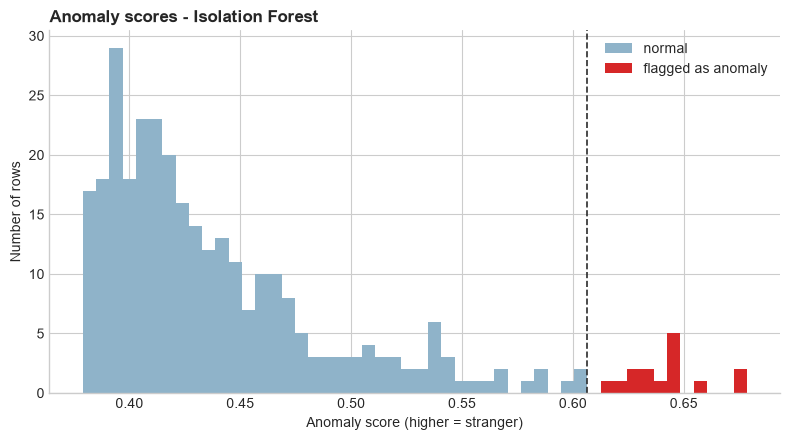

In [8]:
det.plot_scores()

### Consensus: who agrees?
A row flagged by many different methods is the one to inspect first. `consensus()` counts the votes.

In [9]:
votes = det.consensus()
print(votes['votes'].value_counts().sort_index().to_string())
print()
print('rows flagged by more than half of the models :', int(votes['consensus'].sum()))
print('of which are real faults (rows 300-314)      :', int(votes['consensus'].iloc[300:].sum()))

votes
0    286
1     10
2      2
3      3
4      5
5      7
6      2

rows flagged by more than half of the models : 14
of which are real faults (rows 300-314)      : 14


## 1.2 No labels at all
This is the normal situation. Without `y` the report cannot say who is right; it shows **Agreement** (how much a model's ranking matches the others) and `contamination` defaults to 5%. Treat the result as a shortlist to check, not as a verdict.

In [10]:
det2 = MultiModelAnomalyDetector(sensors, contamination=0.05, random_state=0, verbose=False)
m2 = det2.run_all_models()
det2.show_tabular_report(m2, return_df=True)


 ANOMALY DETECTOR COMPARISON 
               Model  Anomalies  Anomaly Rate (%)  Agreement  Fit Time (s)
   Elliptic Envelope         16            5.0794     0.9765        0.0247
        KNN Distance         16            5.0794     0.9640        0.0011
    Isolation Forest         16            5.0794     0.9571        0.1431
Local Outlier Factor         16            5.0794     0.9471        0.0151
      Robust Z-Score         16            5.0794     0.8695        0.0002
       One-Class SVM         16            5.0794     0.7658        0.0015

* BEST MODEL (by Agreement): Elliptic Envelope
  Every model flags the top 5.0% of rows by anomaly score, so the counts are about equal.
  No true labels were given: 'Agreement' only shows which model sees the data like the others.
  Look at top_anomalies() and the plots, and check a few flagged rows yourself.



,Model,Anomalies,Anomaly Rate (%),Agreement,Fit Time (s)
0,Elliptic Envelope,16,5.079365,0.976497,0.024703
1,KNN Distance,16,5.079365,0.963968,0.001068
2,Isolation Forest,16,5.079365,0.957079,0.143069
3,Local Outlier Factor,16,5.079365,0.947078,0.015071
4,Robust Z-Score,16,5.079365,0.869503,0.000168
5,One-Class SVM,16,5.079365,0.765753,0.001536


## 1.3 Judging NEW rows: `predict`, `score_new`, `save_model`
The training scaling and the score threshold travel with the model.

In [11]:
new_rows = pd.DataFrame({'temperature': [0.2, 4.5], 'pressure': [0.1, -4.0], 'vibration': [-0.3, 3.8]})
print('Isolation Forest ->', det.predict(new_rows, model='Isolation Forest'), '(1 = anomaly)')
print('scores           ->', det.score_new(new_rows, model='Isolation Forest').round(3))
path = det.save_model(os.path.join(tempfile.mkdtemp(), 'sensor_iforest.joblib'), model='Isolation Forest')
print('reloaded         ->', mm.load_model(path).predict(new_rows))

Isolation Forest -> [0 1] (1 = anomaly)
scores           -> [0.391 0.627]
reloaded         -> [0 1]


## 1.4 Messy data: `preprocess=True`, your own model
Text columns and missing values are handled automatically; any scikit-learn-style detector can join the comparison.

In [12]:
from sklearn.ensemble import IsolationForest
orders = pd.DataFrame({
    'amount': np.r_[rng.gamma(2, 30, 250), [900, 1200, 15]],
    'items': np.r_[rng.poisson(3, 250), [40, 55, 1]],
    'country': np.r_[rng.choice(['IN', 'US', 'DE'], 250, p=[.5, .3, .2]), ['NG', 'NG', 'IN']],
})
orders.loc[[5, 17, 40], 'amount'] = np.nan
od = MultiModelAnomalyDetector(orders, contamination=0.02, preprocess=True, random_state=0, verbose=False)
om = od.run_all_models(include=['isolation_forest', 'lof', 'robust_zscore'],
                       custom_models={'My Forest (300 trees)': IsolationForest(n_estimators=300, random_state=0)})
od.show_tabular_report(om, return_df=True)
od.top_anomalies(5)


 ANOMALY DETECTOR COMPARISON 
                Model  Anomalies  Anomaly Rate (%)  Agreement  Fit Time (s)
     Isolation Forest          6            2.3715     0.9728        0.1454
My Forest (300 trees)          6            2.3715     0.9724        0.1832
       Robust Z-Score          6            2.3715     0.7086        0.0003
 Local Outlier Factor          6            2.3715     0.6705        0.0146

* BEST MODEL (by Agreement): Isolation Forest
  Every model flags the top 2.0% of rows by anomaly score, so the counts are about equal.
  No true labels were given: 'Agreement' only shows which model sees the data like the others.
  Look at top_anomalies() and the plots, and check a few flagged rows yourself.



,amount,items,country,anomaly,anomaly_score
251,1200.000000,55,NG,1,0.834381
250,900.000000,40,NG,1,0.813154
171,161.212209,8,US,1,0.669255
76,179.915834,6,DE,1,0.655393
211,188.465521,4,US,1,0.626783


# Part 2 - Dimensionality reduction
Many features are hard to plot and slow to model. `MultiModelReducer` fits several reducers, then scores how faithfully each one keeps the structure of your data:

| score | meaning |
|---|---|
| Trustworthiness | rows that are neighbours in the result were neighbours before (1 = perfect) |
| Continuity | neighbours before are still neighbours after (1 = perfect) |
| Global Structure | far-apart rows stay far apart |
| Variance Kept (%) | how much of the original information can be rebuilt (PCA-style methods only) |
| Class Separation | with `y`: how well a 5-nearest-neighbour vote on the new coordinates recovers the labels |

In [13]:
print('standard set :', MultiModelReducer.default_models())
print('everything    :', MultiModelReducer.available_models())

standard set : ['pca', 'kernel_pca', 'fastica', 'factor_analysis', 'isomap', 'lle', 'tsne']
everything    : ['pca', 'kernel_pca', 'fastica', 'factor_analysis', 'isomap', 'lle', 'tsne', 'truncated_svd', 'spectral_embedding', 'mds', 'random_projection', 'umap']


## 2.1 Handwritten digits: 64 pixel features down to 2

In [14]:
digits = load_digits()
Xd, yd = digits.data[:1000], digits.target[:1000]
red = MultiModelReducer(Xd, y=yd, n_components=2, random_state=0, verbose=False)
rmodels = red.run_all_models()
rdf = red.show_tabular_report(rmodels, return_df=True)


 DIMENSIONALITY REDUCTION COMPARISON 
                   Model  Components  Trustworthiness  Continuity  Global Structure  Variance Kept (%)  Class Separation Can Transform New Data  Fit Time (s)
                   t-SNE           2           0.9853      0.9831            0.4018                  -            0.9400                     no        1.1346
                  Isomap           2           0.8722      0.9681            0.5295                  -            0.7360                    yes        0.1515
                     PCA           2           0.8350      0.9435            0.6870            21.8426            0.5630                    yes        0.0020
Locally Linear Embedding           2           0.8130      0.9443            0.1548                  -            0.7270                    yes        0.0708
              Kernel PCA           2           0.8047      0.9331            0.2451                  -            0.6120                    yes        0.0384
         Fact

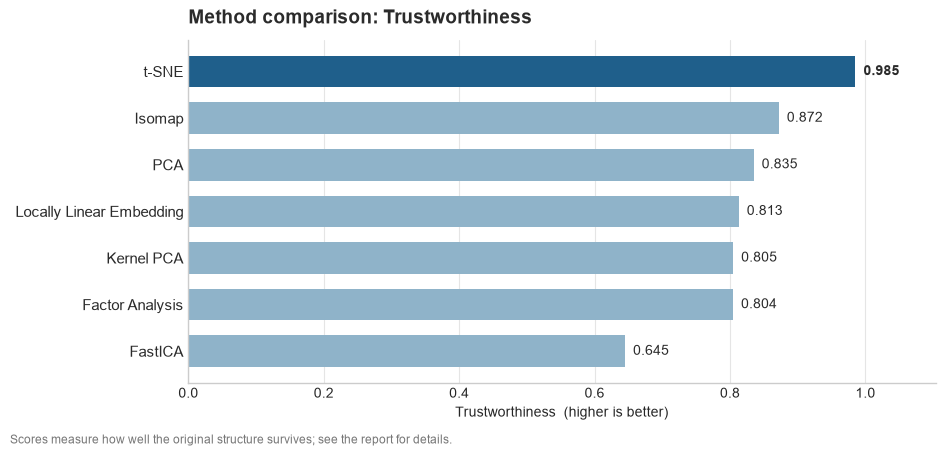

In [15]:
red.plot_comparison(rmodels)

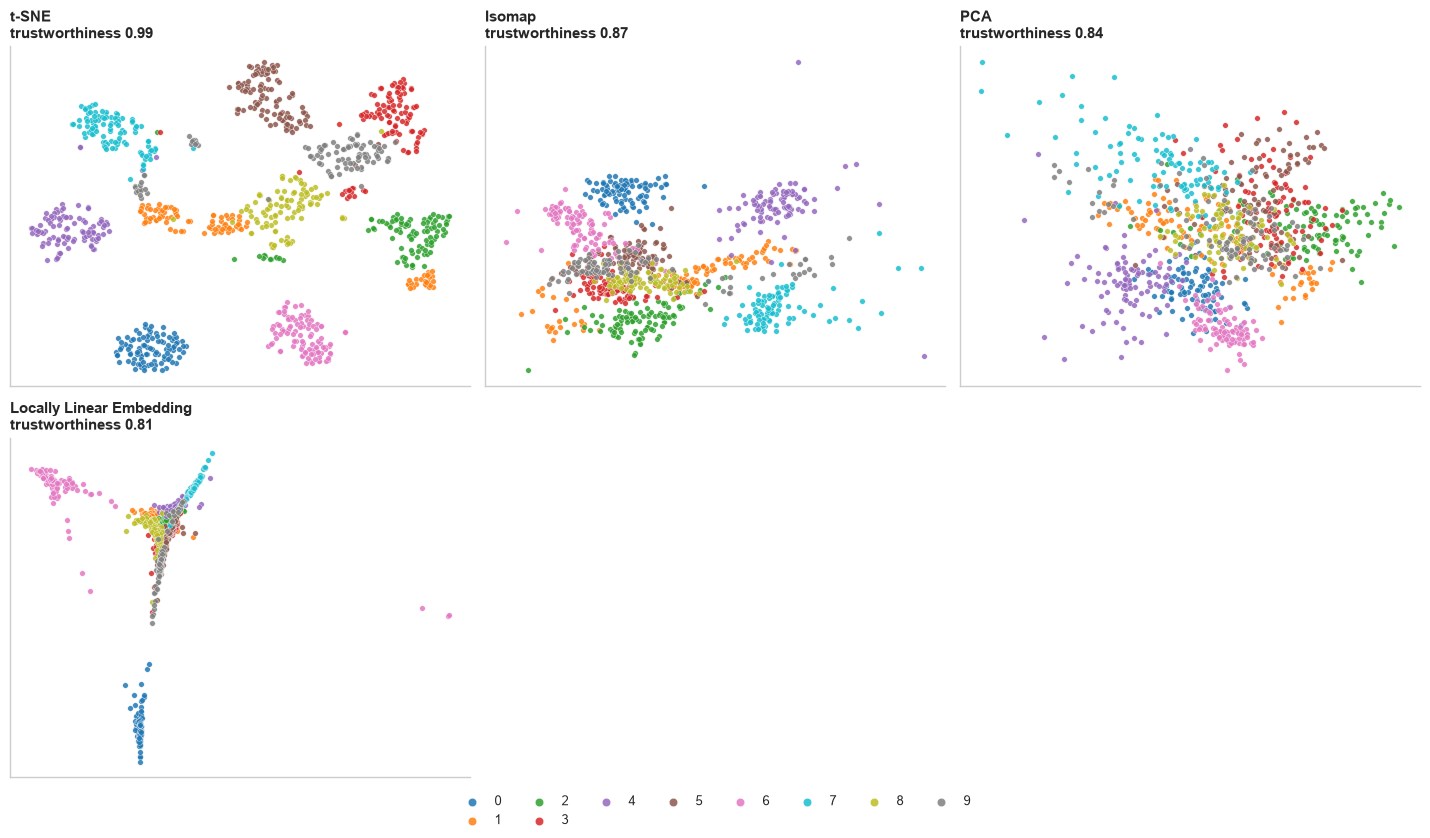

In [16]:
red.plot_embeddings(rmodels, top=4)

Local scores favour t-SNE and Isomap (they preserve neighbourhoods), PCA is the most *explainable* and the only one with Variance Kept. Pick by what you need, not just by the top row.

### How many components do I need? `find_n_components`
The smallest number of PCA components that keep 95% of the variance.

In [17]:
k = red.find_n_components(0.95)

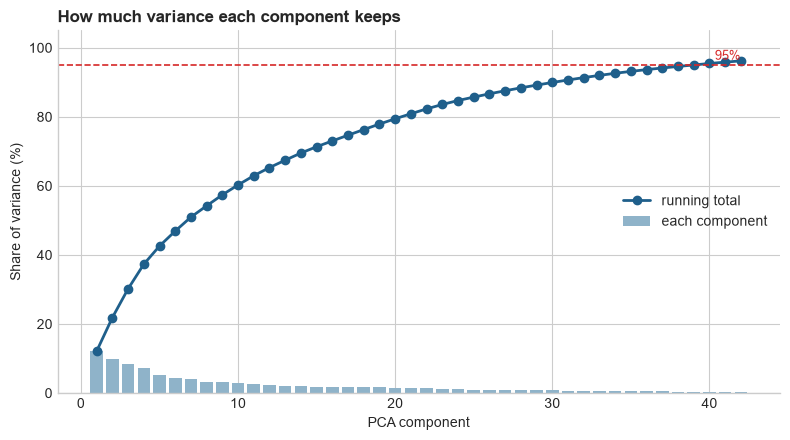

In [18]:
red.plot_variance()

### What does a component mean? `get_loadings`
The loadings say how much each (scaled) original feature contributes. Here the 5 pixels that matter most for component 1.

In [19]:
loads = red.get_loadings('PCA')
loads['Component 1'].abs().sort_values(ascending=False).head(5).round(3)

feature 3     0.256
feature 59    0.243
feature 10    0.229
feature 11    0.222
feature 4     0.216
Name: Component 1, dtype: float64

In [20]:
red.get_embedding('PCA').head()

,Component 1,Component 2
0,-1.462621,-1.481760
1,-0.657289,0.588974
2,-1.153095,-0.769277
3,3.105652,0.377204
4,-3.834991,-2.530604


### Reusing a fitted reducer on new rows
PCA, Kernel PCA, FastICA, Isomap, ... can map new data (`transform`). t-SNE only embeds the rows it was fitted on, so it says so clearly instead of failing silently.

In [21]:
print(red.transform(digits.data[1000:1004], model='PCA').round(2))
try:
    red.transform(digits.data[1000:1004], model='t-SNE')
except TypeError as e:
    print()
    print('TypeError:', e)

   Component 1  Component 2
0         3.01        -1.89
1        -6.61        -1.11
2         0.05        -1.88
3         2.67         2.59

TypeError: 't-SNE' cannot transform new data (it only embeds the rows it was fitted on). Methods that can: ['PCA', 'Kernel PCA', 'FastICA', 'Factor Analysis', 'Isomap', 'Locally Linear Embedding'].


In [22]:
path = red.save_model(os.path.join(tempfile.mkdtemp(), 'digits_pca.joblib'), model='PCA')
print('reloaded ->', mm.load_model(path).transform(digits.data[1000:1002]).round(2).tolist())

reloaded -> [[3.01, -1.89], [-6.61, -1.11]]


## 2.2 A curved surface: where linear PCA fails
A swiss roll is a flat sheet rolled up in 3-D. PCA can only squash it; Isomap, LLE and t-SNE can *unroll* it. The colour is the position along the sheet; we pass it as `y` only to colour the plots.

In [23]:
roll, t = make_swiss_roll(n_samples=1200, noise=0.05, random_state=0)
sr = MultiModelReducer(roll, y=t, n_components=2, random_state=0, verbose=False)
sm = sr.run_all_models(include=['pca', 'isomap', 'lle', 'tsne'])
sr.show_tabular_report(sm, return_df=True)


 DIMENSIONALITY REDUCTION COMPARISON 
                   Model  Components  Trustworthiness  Continuity  Global Structure  Variance Kept (%) Can Transform New Data  Fit Time (s)
                   t-SNE           2           0.9996      0.9979            0.3564                  -                     no        1.4433
                  Isomap           2           0.9994      0.9993            0.3729                  -                    yes        0.2041
Locally Linear Embedding           2           0.9964      0.9965            0.3380                  -                    yes        0.0664
                     PCA           2           0.8617      0.9940            0.8274            70.2681                    yes        0.0003

* BEST MODEL (by Trustworthiness): t-SNE
  Trustworthiness / Continuity: 1.0 = neighbourhoods are perfectly kept. Global Structure: how well
  far-apart rows stay far apart. Variance Kept: only for methods that can be reversed (PCA, ...).
  Local scores favour

,Model,Components,Trustworthiness,Continuity,Global Structure,Variance Kept (%),Can Transform New Data,Fit Time (s)
0,t-SNE,2,0.999552,0.997918,0.356410,NaN,no,1.443261
1,Isomap,2,0.999421,0.999297,0.372909,NaN,yes,0.204144
2,Locally Linear Embedding,2,0.996436,0.996488,0.337950,NaN,yes,0.066374
3,PCA,2,0.861670,0.993977,0.827400,70.268128,yes,0.000316


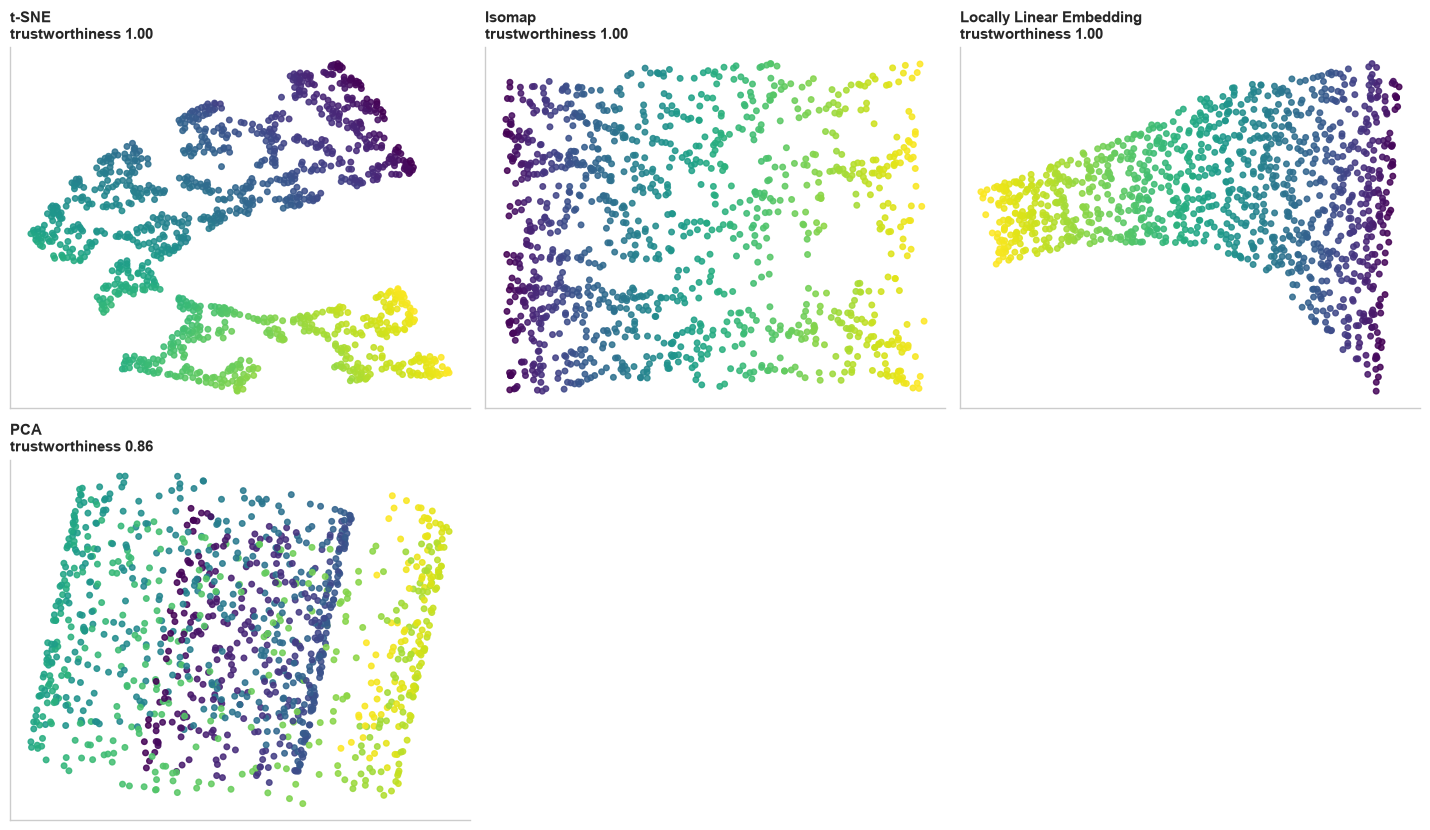

In [24]:
sr.plot_embeddings(sm, top=4)

## 2.3 Reducing before clustering
A reducer is often the first step of a pipeline. Here: 4 iris features -> 2 components -> clusters, compared with clustering the raw features.

In [25]:
iris = load_iris(as_frame=True)
ir = MultiModelReducer(iris.data, y=iris.target, n_components=2, random_state=0, verbose=False)
ir.run_all_models(include=['pca', 'isomap'])
ir.show_tabular_report(return_df=True)
emb = ir.get_embedding('PCA')
for label, data in [('raw 4 features', iris.data), ('2 PCA components', emb)]:
    c = MultiModelClusterer(data, y=iris.target, n_clusters=3, random_state=0, verbose=False)
    out = c.run_all_models(include=['kmeans', 'gaussian_mixture'])
    table = c.show_tabular_report(out, return_df=True)
    print(f'--- {label}')
    print(table[['Model', 'Silhouette', 'ARI']].round(3).to_string(index=False))


 DIMENSIONALITY REDUCTION COMPARISON 
 Model  Components  Trustworthiness  Continuity  Global Structure  Variance Kept (%)  Class Separation Can Transform New Data  Fit Time (s)
   PCA           2           0.9780      0.9906            0.9934            95.8132            0.9133                    yes        0.0006
Isomap           2           0.9691      0.9849            0.9428                  -            0.8867                    yes        0.0188

* BEST MODEL (by Trustworthiness): PCA
  Trustworthiness / Continuity: 1.0 = neighbourhoods are perfectly kept. Global Structure: how well
  far-apart rows stay far apart. Variance Kept: only for methods that can be reversed (PCA, ...).
  Local scores favour t-SNE / Isomap; PCA keeps the global shape and is the easiest to explain.




 CLUSTERING MODEL COMPARISON 
           Model  Clusters  Noise Points  Silhouette  Calinski-Harabasz  Davies-Bouldin    ARI    NMI  V-measure  Homogeneity  Completeness  Fit Time (s)
          KMeans         3             0      0.4599           241.9044          0.8336 0.6201 0.6595     0.6595       0.6591        0.6598        0.0163
Gaussian Mixture         3             0      0.3742           187.7745          1.0809 0.9039 0.8997     0.8997       0.8983        0.9011        0.0339

* BEST MODEL (by Silhouette): KMeans  - 3 clusters, Silhouette 0.4599
  Silhouette: above 0.5 = clear groups, 0.25-0.5 = reasonable, below 0.25 = weak structure.
  Davies-Bouldin: lower is better. Noise points (label -1) are left out of the scores.
  ARI / NMI compare with the TRUE labels you passed as y (1.0 = perfect match).

--- raw 4 features
           Model  Silhouette   ARI
          KMeans       0.460 0.620
Gaussian Mixture       0.374 0.904

 CLUSTERING MODEL COMPARISON 
           Model  Clu

# Part 3 - Explainability
A model that scores 98% is not useful until you know *why*. Two tools, both computed on the **test split** (data the model has not seen) and both available for every classifier and regressor, including the optional boosters:

- **Permutation importance** - shuffle one feature and see how much the score drops. A big drop means the model relies on it; zero means it ignores it.
- **Partial dependence** - sweep one feature over its range and watch the average prediction move.

## 3.1 Classification: breast cancer

In [26]:
cancer = load_breast_cancer(as_frame=True)
clf = MultiModelClassifier(cancer.data, cancer.target, random_state=0, verbose=False)
cm = clf.run_all_models(include=['logistic_regression', 'random_forest', 'gradient_boosting'])
clf.show_tabular_report(cm, return_df=True)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision   Recall  F1 Score  ROC AUC  Fit Time (s)
Logistic Regression  0.959064   0.959259 0.959064  0.959127 0.995619      0.006572
      Random Forest  0.953216   0.953187 0.953216  0.953062 0.978023      0.091257
  Gradient Boosting  0.935673   0.935936 0.935673  0.935771 0.986273      0.183606

* BEST MODEL RECOMMENDATION (by Accuracy): Logistic Regression
   Accuracy: 0.9591 | F1 Score: 0.9591



,Model,Accuracy,Precision,Recall,F1 Score,ROC AUC,Fit Time (s)
0,Logistic Regression,0.959064,0.959259,0.959064,0.959127,0.995619,0.006572
1,Random Forest,0.953216,0.953187,0.953216,0.953062,0.978023,0.091257
2,Gradient Boosting,0.935673,0.935936,0.935673,0.935771,0.986273,0.183606


In [27]:
clf.feature_importance().head(8)

,Feature,Importance,Std
0,radius error,0.011111,0.007602
1,perimeter error,0.008187,0.007018
2,worst symmetry,0.007602,0.003745
3,worst texture,0.007018,0.008595
4,area error,0.006433,0.007138
5,mean concave points,0.005848,0.009430
6,compactness error,0.005263,0.009942
7,mean concavity,0.004678,0.006820


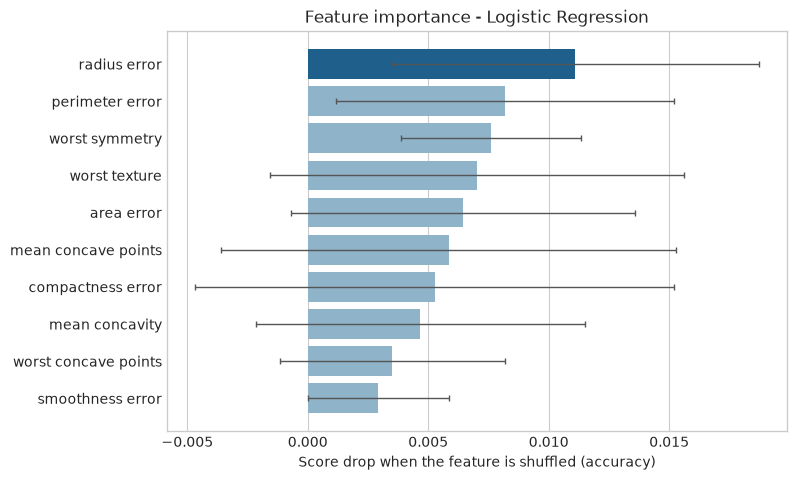

In [28]:
clf.plot_feature_importance(top=10)

Importance is in **accuracy points**: a bar of 0.01 means shuffling that feature costs one point; the whiskers show how much that varies over 10 shuffles. Features whose whisker crosses zero are not reliably useful - on a small test split like this one (171 rows) most differences are small, which is itself a finding: many correlated features share the work.

Other models can be asked too - and may disagree, which is informative:

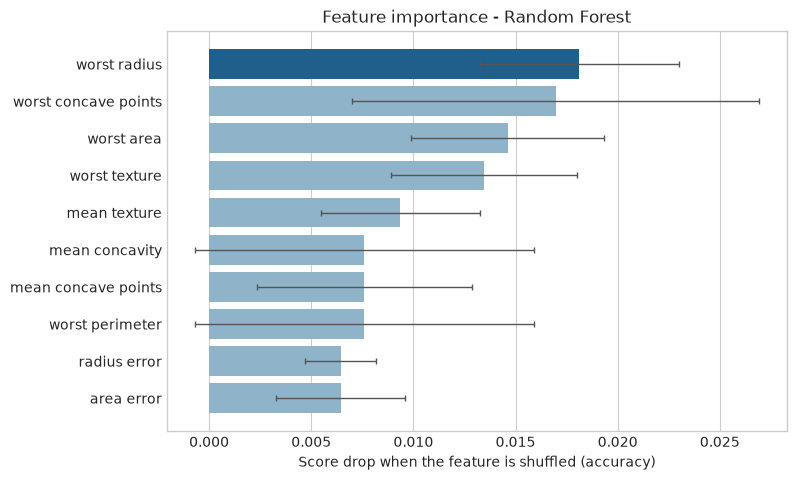

In [29]:
clf.plot_feature_importance(model='Random Forest', top=10)

### How does a feature change the prediction?
By default the three most important features are drawn. The vertical axis is the probability of the last class (here class 1 = *benign*); the x axis is in standardised units (0 = average).

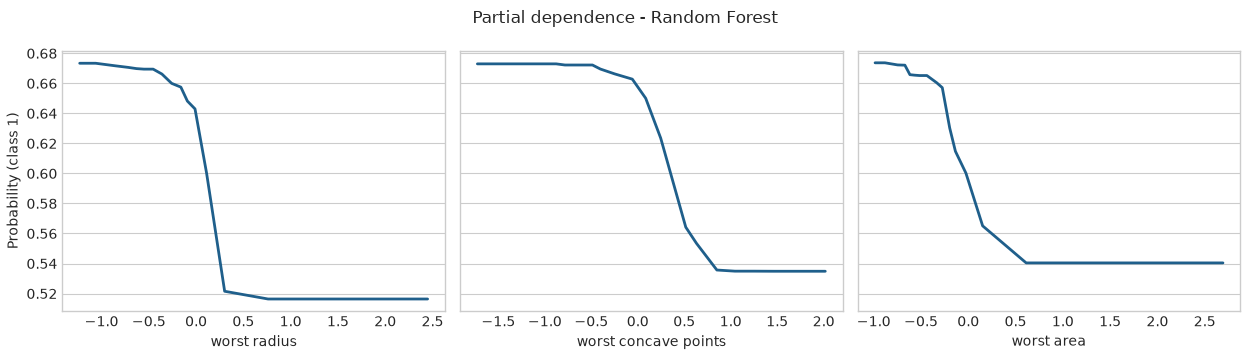

In [30]:
clf.plot_partial_dependence(model='Random Forest')

     Feature  Feature value  Probability         Model
worst radius         -1.231        0.673 Random Forest
worst radius         -0.643        0.670 Random Forest
worst radius         -0.413        0.666 Random Forest
worst radius         -0.054        0.647 Random Forest
worst radius          0.782        0.516 Random Forest
worst radius          2.448        0.516 Random Forest


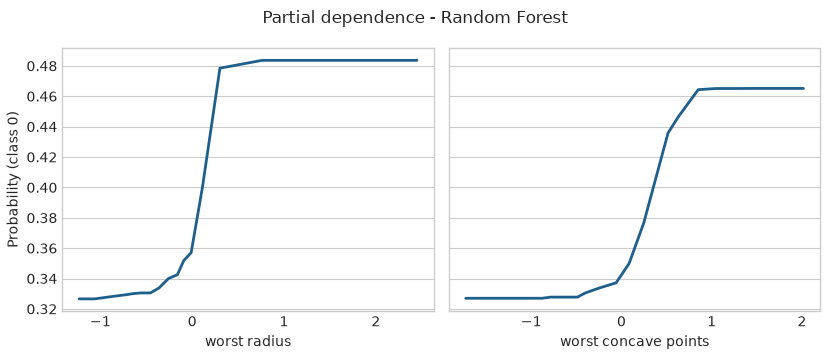

In [31]:
# the numbers behind a curve, and the other class
print(clf.partial_dependence('worst radius', model='Random Forest', grid_points=6).round(3).to_string(index=False))
clf.plot_partial_dependence(['worst radius', 'worst concave points'], model='Random Forest', class_label=0)

## 3.2 Regression: diabetes progression

In [32]:
diab = load_diabetes(as_frame=True)
reg = MultiModelRegressor(diab.data, diab.target, random_state=0, verbose=False)
rm = reg.run_all_models(include=['linear_regression', 'random_forest', 'hist_gradient_boosting'])
reg.show_tabular_report(rm, return_df=True)


 REGRESSION MODEL COMPARISON TABLE 
                           Model       MAE         MSE      RMSE  R2 Score  Fit Time (s)
               Linear Regression 44.617595 3097.119163 55.651767  0.392899      0.000705
         Random Forest Regressor 47.750977 3510.752319 59.251602  0.311818      0.071462
Hist Gradient Boosting Regressor 46.540898 3679.589109 60.659617  0.278723      0.096876

* BEST MODEL RECOMMENDATION (by R2 Score): Linear Regression
   R2 Score: 0.3929 | RMSE: 55.6518



,Model,MAE,MSE,RMSE,R2 Score,Fit Time (s)
0,Linear Regression,44.617595,3097.119163,55.651767,0.392899,0.000705
1,Random Forest Regressor,47.750977,3510.752319,59.251602,0.311818,0.071462
2,Hist Gradient Boosting Regressor,46.540898,3679.589109,60.659617,0.278723,0.096876


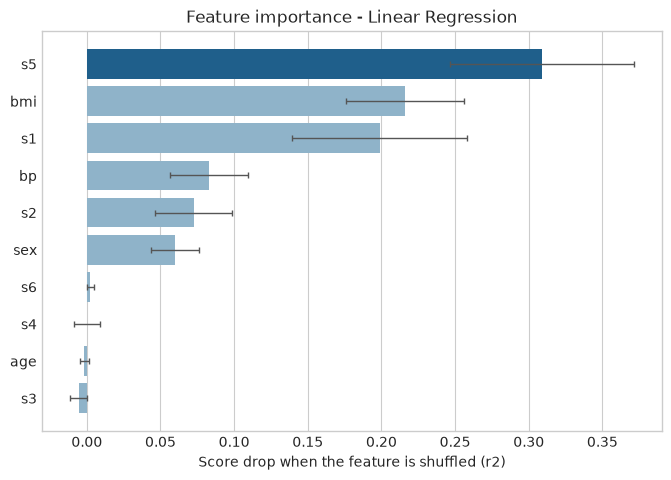

In [33]:
reg.plot_feature_importance(top=10)

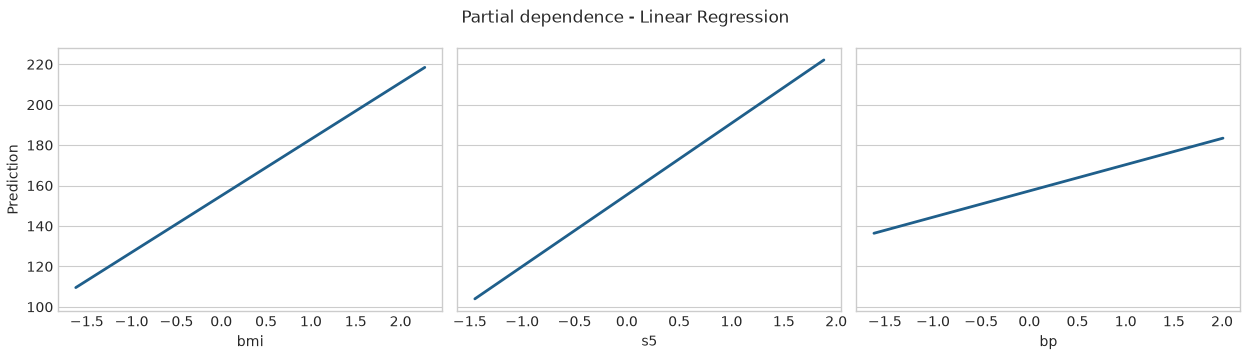

In [34]:
reg.plot_partial_dependence(['bmi', 's5', 'bp'])

Importance now is in **R2 points**. Body-mass index (`bmi`) and `s5` (a blood-serum measure) dominate; the curves show disease progression rising with both.

## 3.3 Works with `preprocess=True` too
One-hot encoded text columns show up as separate features (e.g. `cat__colour_red`).

In [35]:
rng = np.random.RandomState(0)
df = pd.DataFrame({'num': rng.randn(300), 'noise': rng.randn(300), 'colour': rng.choice(['red', 'green', 'blue'], 300)})
target = np.where(df['num'] + (df['colour'] == 'red') * 1.5 > 0.8, 'buy', 'skip')
pc = MultiModelClassifier(df, target, preprocess=True, random_state=0, verbose=False)
pm = pc.run_all_models(include=['logistic_regression', 'random_forest'])
pc.show_tabular_report(pm, return_df=True)
pc.feature_importance().round(3)


 MODEL COMPARISON TABLE 
              Model  Accuracy  Precision  Recall  F1 Score  ROC AUC  Fit Time (s)
Logistic Regression       1.0        1.0     1.0       1.0      1.0      0.003088
      Random Forest       1.0        1.0     1.0       1.0      1.0      0.086257

* BEST MODEL RECOMMENDATION (by Accuracy): Logistic Regression
   Accuracy: 1.0000 | F1 Score: 1.0000



,Feature,Importance,Std
0,num,0.360,0.041
1,colour_red,0.156,0.031
2,colour_green,0.080,0.027
3,colour_blue,0.050,0.019
4,noise,0.003,0.005


# Part 4 - One shareable HTML report
`save_html_report()` writes a single file: results table, all the plots of the analyser (embedded, so nothing else is needed), failed models and warnings. It works for **every** analyser - classifier, regressor, clusterer, anomaly detector and reducer. Run `show_tabular_report()` first so the file knows which model ranks first.

In [36]:
out_dir = tempfile.mkdtemp()
files = {
    'classification': clf.save_html_report(os.path.join(out_dir, 'classification.html'), title='Breast cancer classification'),
    'regression': reg.save_html_report(os.path.join(out_dir, 'regression.html'), title='Diabetes regression'),
    'anomaly': det.save_html_report(os.path.join(out_dir, 'anomaly.html'), title='Sensor anomalies'),
    'reduction': red.save_html_report(os.path.join(out_dir, 'reduction.html'), title='Digits reduction'),
}
for name, p in files.items():
    print(f'{name:15s} {os.path.getsize(p) / 1024:6.0f} KB')

[INFO] HTML report saved to 'C:\Users\uditm\AppData\Local\Temp\tmpiicmzl6w\classification.html'.


[INFO] HTML report saved to 'C:\Users\uditm\AppData\Local\Temp\tmpiicmzl6w\regression.html'.


[INFO] HTML report saved to 'C:\Users\uditm\AppData\Local\Temp\tmpiicmzl6w\anomaly.html'.


[INFO] HTML report saved to 'C:\Users\uditm\AppData\Local\Temp\tmpiicmzl6w\reduction.html'.
classification     246 KB
regression         291 KB
anomaly            188 KB
reduction          431 KB


In [37]:
import re
text = open(files['classification'], encoding='utf-8').read()
print('sections :', re.findall(r'<h2>(.*?)</h2>', text))
print('plots    :', text.count('data:image/png;base64,'), 'embedded images, no external files')

sections : ['Results', 'Model comparison', 'Confusion matrices', 'ROC curves', 'Which features matter (Logistic Regression)', 'How the top features change the prediction (Logistic Regression)']
plots    : 5 embedded images, no external files


A copy of the classification report is saved as `examples/phase7_report.html` - open it in your browser to see exactly what a colleague would receive.

In [38]:
import shutil
target_dir = 'examples' if os.path.isdir('examples') else '.'
shutil.copy(files['classification'], os.path.join(target_dir, 'phase7_report.html'))
print('saved', os.path.join(target_dir, 'phase7_report.html'))

saved .\phase7_report.html


## Summary of what is new
| You want to... | Use |
|---|---|
| find strange rows | `MultiModelAnomalyDetector(X).run_all_models()` -> `top_anomalies()`, `consensus()` |
| shrink many features to a few | `MultiModelReducer(X, n_components=2)` -> `plot_embeddings()`, `find_n_components()` |
| know *which* features a model uses | `feature_importance()`, `plot_feature_importance()` |
| know *how* a feature moves the prediction | `partial_dependence()`, `plot_partial_dependence()` |
| hand results to someone else | `save_html_report('report.html')` |